# Simulated ARMA(1,1)–GARCH(1,1) — recovering the DGP with makystats

**Goal.** Show that joint MLE recovers **both** autoregressive and moving-average mean lags **and** GARCH variance parameters when the data-generating process is known.

**DGP (known).**
\[
\begin{aligned}
y_t &= 0.05 + 0.40\, y_{t-1} + \varepsilon_t + 0.30\,\varepsilon_{t-1},\\
\sigma_t^2 &= 0.05 + 0.08\,\varepsilon_{t-1}^2 + 0.90\,\sigma_{t-1}^2,\\
\varepsilon_t &= \sigma_t z_t,\quad z_t \sim \mathcal{N}(0,1).
\end{aligned}
\]

This is the cleanest way to demonstrate **AR + MA + GARCH together** without near-cancellation artefacts common on daily equity excess returns.

**Links.** [PyPI](https://pypi.org/project/makystats/) · [Docs](https://lauret-boris.github.io/makystats/) · [GitHub](https://github.com/Lauret-Boris/makystats)


## 1. Setup


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from makystats import arma_garch, select_order
from statsmodels.stats.diagnostic import acorr_ljungbox

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["figure.figsize"] = (11, 4.0)

## 2. Simulate the DGP


In [2]:
rng = np.random.default_rng(42)
n = 3000
z = rng.standard_normal(n)
eps = np.empty(n)
sig2 = np.empty(n)
y = np.empty(n)

omega, alpha, beta = 0.05, 0.08, 0.90
sig2[0] = omega / (1 - alpha - beta)
eps[0] = np.sqrt(sig2[0]) * z[0]
y[0] = 0.05 + eps[0]
for t in range(1, n):
    sig2[t] = omega + alpha * eps[t - 1] ** 2 + beta * sig2[t - 1]
    eps[t] = np.sqrt(sig2[t]) * z[t]
    y[t] = 0.05 + 0.40 * y[t - 1] + eps[t] + 0.30 * eps[t - 1]

y = pd.Series(y, name="y")
true = {"const": 0.05, "AR(1)": 0.40, "MA(1)": 0.30, "omega": 0.05, "alpha(1)": 0.08, "beta(1)": 0.90}
print(y.describe().round(3))


count    3000.000
mean       -0.002
std         2.009
min        -8.258
25%        -1.239
50%         0.032
75%         1.260
max         8.072
Name: y, dtype: float64


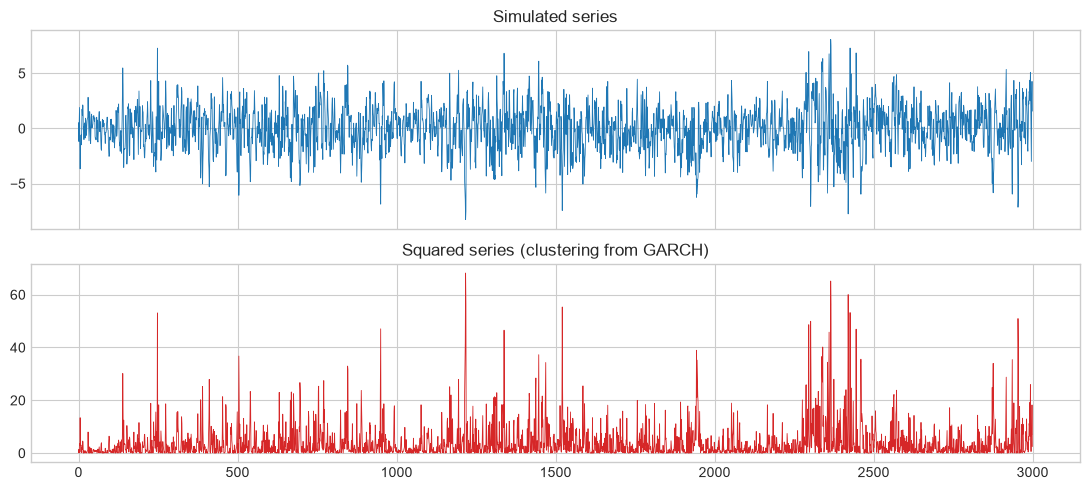

Ljung–Box on levels


,lb_stat,lb_pvalue
5,1371.1297,0.0
10,1376.4360,0.0
20,1388.7868,0.0


Ljung–Box on squares


,lb_stat,lb_pvalue
5,774.1546,0.0
10,916.5987,0.0
20,1060.0092,0.0


In [3]:
fig, axes = plt.subplots(2, 1, figsize=(11, 5), sharex=True)
axes[0].plot(y, lw=0.6)
axes[0].set_title("Simulated series")
axes[1].plot(y**2, lw=0.6, color="C3")
axes[1].set_title("Squared series (clustering from GARCH)")
fig.tight_layout()
plt.show()

def lb(series, title):
    d = acorr_ljungbox(series, lags=[5, 10, 20], return_df=True)
    print(title)
    display(d.round(4))

lb(y - y.mean(), "Ljung–Box on levels")
lb((y - y.mean()) ** 2, "Ljung–Box on squares")


**Reading.** Strong dependence in **levels** (ARMA) and in **squares** (GARCH). A variance-only model cannot clean residual serial correlation; a mean-only model cannot clean residual energy.


## 3. Weak model: constant mean + GARCH only


In [4]:
def report(name, res):
    print("=== %s ===" % name)
    print("LogL=%.2f  AIC=%.2f  BIC=%.2f" % (res.loglik, res.aic, res.bic))
    print("LB resid p=%.4g | LB resid2 p=%.4g" % (res.ljungbox_resid_pval, res.ljungbox_resid2_pval))
    display(res.coef_table.round(4))

res_weak = arma_garch(
    y, mean="Constant", ar=0, ma=0, vol="GARCH", r=1, s=1, dist="normal", trend="c"
).fit(verbose=False)
res_weak.summary()


   ARMA(0,0) - GARCH(1,1) — MLE (MLE)
   Mean: Constant  |  trend=c  |  Distribution: NORMAL  |  Optimiseur: BFGS non contraint (reparam.)
   Backcast exponentiel: lambda = 0.7  |  Cov: OPG
Log-Likelihood : -6117.925859
AIC            : 12243.8517
BIC            : 12267.8772
Observations   : 3000
Paramètres     : 4

--- Coefficients (IC 95% dans self.coef_table) ---
             Coeff   Std.Err     z-Stat     Prob.  CI_low_95  CI_high_95
const     0.038697  0.032925   1.175308  0.239871  -0.025835    0.103229
omega     0.938358  0.105536   8.891386  0.000000   0.731512    1.145204
alpha(1)  0.385669  0.033666  11.455847  0.000000   0.319685    0.451652
beta(1)   0.401498  0.034834  11.525945  0.000000   0.333224    0.469772

--- Diagnostic ---
alpha+beta = 0.787167
Ljung-Box (10) sur résidus std : p-val = 0.0000
Ljung-Box (10) sur carrés std  : p-val = 0.0000
Jarque-Bera (normalité résidus std) : stat=0.1677  p-val=0.9196


**Diagnosis.** Ljung–Box on residuals remains catastrophic: GARCH absorbed clustering but not the ARMA mean. **Both** blocks are required.


## 4. Full DGP class: ARMA(1,1)–GARCH(1,1)


In [5]:
res = arma_garch(
    y, mean="ARMA", ar=1, ma=1, vol="GARCH", r=1, s=1, dist="normal", trend="c"
).fit(verbose=False)
report("ARMA(1,1)–GARCH(1,1) normal", res)

est = res.coef_table["Coeff"]
# Build comparison with aligned index (pandas 2.x / 3.x safe)
cmp = pd.DataFrame({
    "true": [true[k] for k in true],
    "estimate": [float(est[k]) if k in est.index else float("nan") for k in true],
}, index=list(true.keys()))
cmp["abs_error"] = (cmp["estimate"] - cmp["true"]).abs()
display(cmp.round(4))

=== ARMA(1,1)–GARCH(1,1) normal ===
LogL=-5474.56  AIC=10961.13  BIC=10997.17
LB resid p=0.1306 | LB resid2 p=0.6285


,Coeff,Std.Err,z-Stat,Prob.,CI_low_95,CI_high_95
const,0.0103,0.0579,0.1782,0.8586,-0.1031,0.1238
AR(1),0.4089,0.0261,15.6879,0.0000,0.3578,0.4600
MA(1),0.3279,0.0273,12.0162,0.0000,0.2744,0.3814
omega,0.0466,0.0142,3.2807,0.0010,0.0188,0.0744
alpha(1),0.0702,0.0101,6.9420,0.0000,0.0504,0.0900
beta(1),0.9119,0.0130,69.9746,0.0000,0.8864,0.9375


,true,estimate,abs_error
const,0.05,0.0103,0.0397
AR(1),0.40,0.4089,0.0089
MA(1),0.30,0.3279,0.0279
omega,0.05,0.0466,0.0034
alpha(1),0.08,0.0702,0.0098
beta(1),0.90,0.9119,0.0119


**Diagnosis.** AR(1) and MA(1) are both recovered near the true values; \(\alpha,\beta,\omega\) match the GARCH DGP; residual Ljung–Box becomes acceptable. This is joint MLE doing its job — not two-step ARMA then GARCH.


## 5. Theory-guided `select_order` (makystats)

One call explores the mean–variance grid under a **common burn-in**, so AIC/BIC are comparable across orders.

| Choice | Grid | Reason |
|--------|------|--------|
| p, q | 0…2 | Allow ARMA(1,1) and neighbours |
| r, s | 1 | GARCH(1,1) workhorse |
| dist | normal | Matches the DGP |
| `mean` | **`"AR"`** | Required for the search helper: it varies p and q. Do **not** pass `mean="ARMA"` here (that path expects ARMAX/exog and fails). |
| criterion | BIC | Recover the parsimonious true order |

`return_best=True` refits the winner so diagnostics use the same object API as a hand-specified `arma_garch(...).fit()`.


In [6]:
table, best = select_order(
    y,
    p_range=range(0, 3),
    q_range=range(0, 3),
    r_range=[1],
    s_range=[1],
    dist=["normal"],
    variance_model=["garch"],
    criterion="bic",
    mean="AR",          # varies AR/MA lags; not mean="ARMA"
    trend="c",
    verbose=False,
    n_jobs=1,
    return_best=True,
)
display(table[["aic", "bic", "ok"]].sort_values("bic").head(8))
print("Best by BIC:", table.attrs.get("best"))
print(best.coef_table.round(4))

,aic,bic,ok
label,,,
"ARMA(1,1)-garch(1,1)-normal",10957.776710,10993.810914,True
"ARMA(1,2)-garch(1,1)-normal",10959.773649,11001.813554,True
"ARMA(2,1)-garch(1,1)-normal",10960.054818,11002.094723,True
"ARMA(2,0)-garch(1,1)-normal",10972.322478,11008.356682,True
"ARMA(2,2)-garch(1,1)-normal",10962.054769,11010.100374,True
"ARMA(0,2)-garch(1,1)-normal",10984.871094,11020.905298,True
"ARMA(1,0)-garch(1,1)-normal",11071.963235,11101.991739,True
"ARMA(0,1)-garch(1,1)-normal",11145.837594,11175.866097,True


Best by BIC: ARMA(1,1)-garch(1,1)-normal
           Coeff  Std.Err   z-Stat   Prob.  CI_low_95  CI_high_95
const     0.0103   0.0579   0.1782  0.8586    -0.1031      0.1238
AR(1)     0.4089   0.0261  15.6879  0.0000     0.3578      0.4600
MA(1)     0.3279   0.0273  12.0162  0.0000     0.2744      0.3814
omega     0.0466   0.0142   3.2807  0.0010     0.0188      0.0744
alpha(1)  0.0702   0.0101   6.9420  0.0000     0.0504      0.0900
beta(1)   0.9119   0.0130  69.9746  0.0000     0.8864      0.9375


## 6. Diagnostics on the BIC-selected model


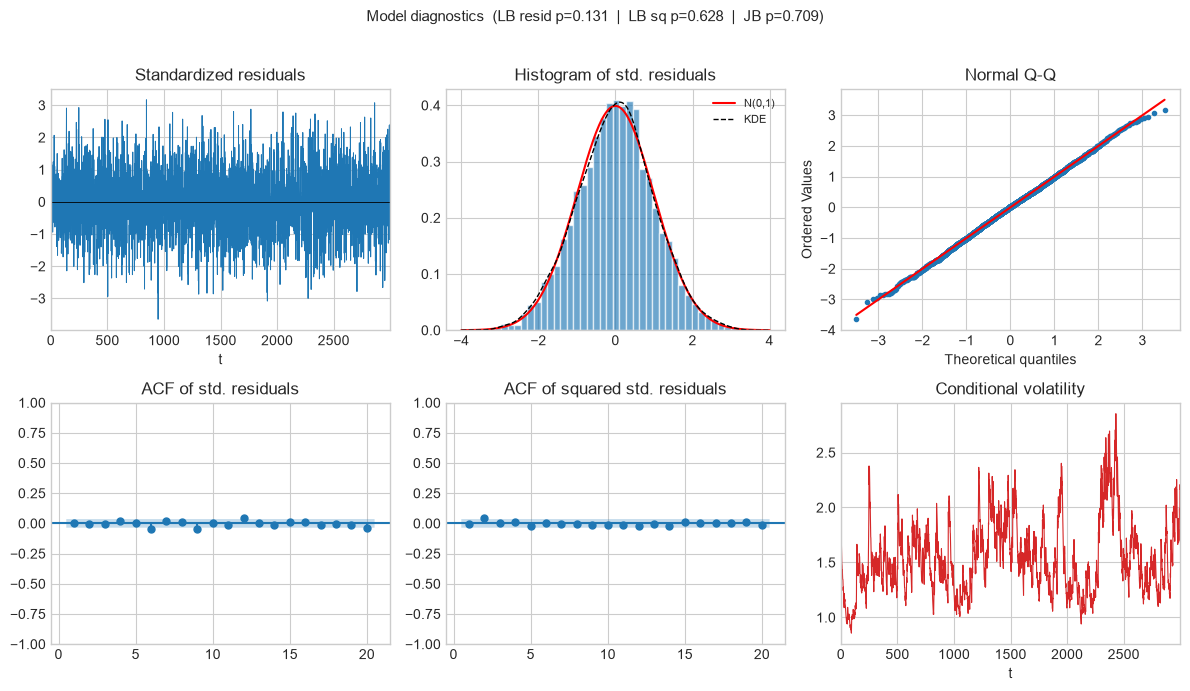

In [7]:
res = best  # from select_order(..., return_best=True)
fig = res.plot_diagnostics()
plt.show()

## 7. Takeaways

1. When the mean is truly ARMA, **constant+GARCH is not enough** — residual Ljung–Box fails hard.
2. Hand-specified **ARMA(1,1)–GARCH(1,1)** recovers AR, MA and variance parameters under joint MLE.
3. **`select_order`** with a tight grid finds the same class by BIC — lags are searched systematically, not guessed.
4. Use **`mean="AR"`** inside `select_order` so p and q vary; keep `mean="ARMA"` for a **single** explicit `arma_garch` fit when you already know the orders.
